In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.api import Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from tqdm import  tqdm
import warnings
warnings.filterwarnings('ignore')
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [3]:
df = pd.read_csv('Electric_Production.csv')
df.shape

(397, 2)

In [4]:
y = df['IPG2211A2N']
y_train,y_test = y.iloc[:-12],y.iloc[-12:]
y_train.shape,y_test.shape

((385,), (12,))

### Simple Exponential smoothing

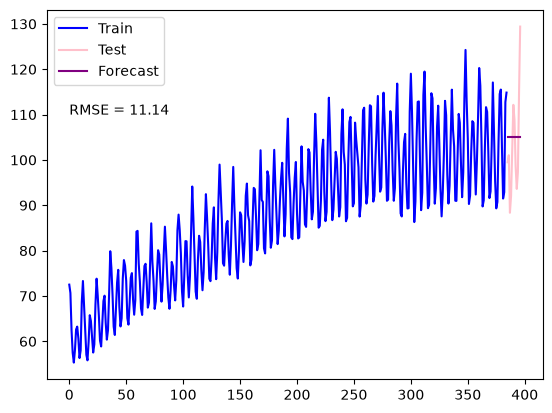

In [8]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train, initialization_method='estimated')
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,110,f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

### Holt's Linear Trend (Additive):

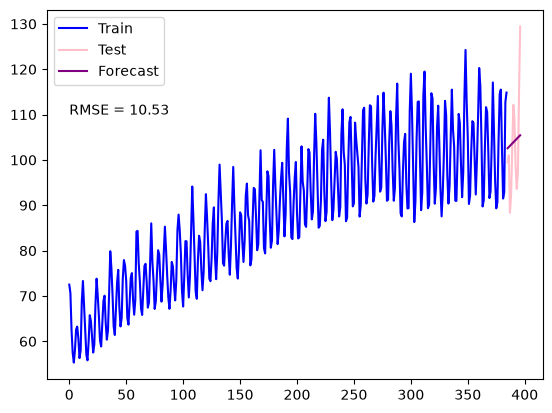

In [10]:
alpha,beta = 0.1,0.2
holt  = Holt(y_train, initialization_method='estimated')
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,110, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


### Holt's Exponential Trend (Multiplicative):

In [19]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)

scores = []

for a in tqdm(alpha):
    for b in beta:
        for e in [True,False]:
            holt  = Holt(y_train, initialization_method='estimated',exponential=e) 
            fit1 = holt.fit(smoothing_level=a,smoothing_trend=b)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,e,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['alpha','beta','Exponential','score'])
df_scores.sort_values('score',ascending=True)



100%|██████████| 10/10 [00:05<00:00,  1.79it/s]


,alpha,beta,Exponential,score
25,0.118889,0.227778,False,10.598056
24,0.118889,0.227778,True,10.628658
22,0.118889,0.118889,True,10.747080
23,0.118889,0.118889,False,10.754211
5,0.010000,0.227778,False,10.834602
...,...,...,...,...
158,0.772222,0.990000,True,145.574333
156,0.772222,0.881111,True,145.578916
136,0.663333,0.881111,True,174.219145
118,0.554444,0.990000,True,194.500365


### damped trend (Holt's)

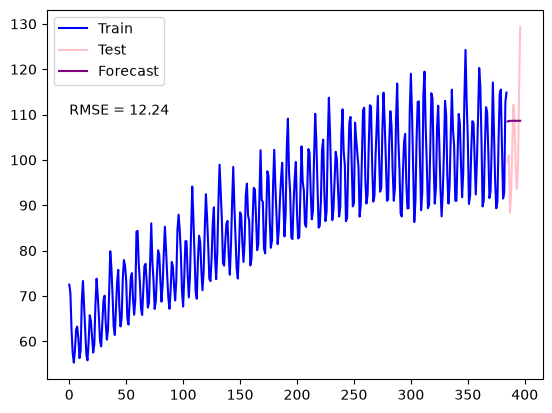

In [16]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(0,110, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Damped Exponential (Holt's)

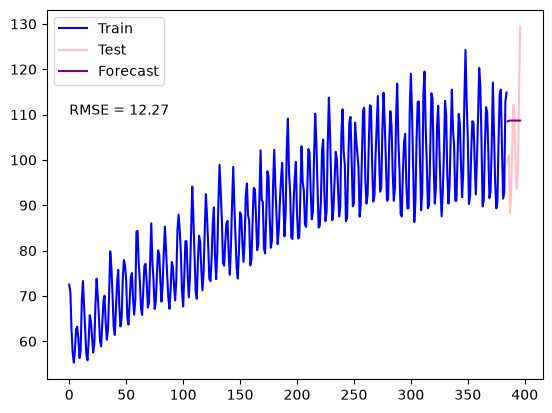

In [15]:
alpha,beta ,phi= 0.4,0.2,0.3
holt  = Holt(y_train, initialization_method='estimated',damped_trend=True,exponential=True) 
fit1 = holt.fit(smoothing_level=alpha,smoothing_trend=beta,damping_trend=phi,optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,110, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()


## Holt's Seasonal Exponential

In [17]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in ['add','mul']:
                hw_add = ExponentialSmoothing(y_train,seasonal_periods=7,trend = 'add',seasonal = s)
                fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
                fcast1 = fit1.forecast(len(y_test))
                scores.append([s,a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['seasonality','alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 10/10 [01:46<00:00, 10.62s/it]


,seasonality,alpha,beta,gamma,score
241,mul,0.118889,0.227778,0.010000,1.066878e+01
240,add,0.118889,0.227778,0.010000,1.068151e+01
220,add,0.118889,0.118889,0.010000,1.082605e+01
221,mul,0.118889,0.118889,0.010000,1.082667e+01
40,add,0.010000,0.227778,0.010000,1.091862e+01
...,...,...,...,...,...
1778,add,0.881111,0.881111,0.990000,6.588626e+09
1798,add,0.881111,0.990000,0.990000,1.468003e+11
1996,add,0.990000,0.990000,0.881111,6.950544e+11
1978,add,0.990000,0.881111,0.990000,4.413787e+12


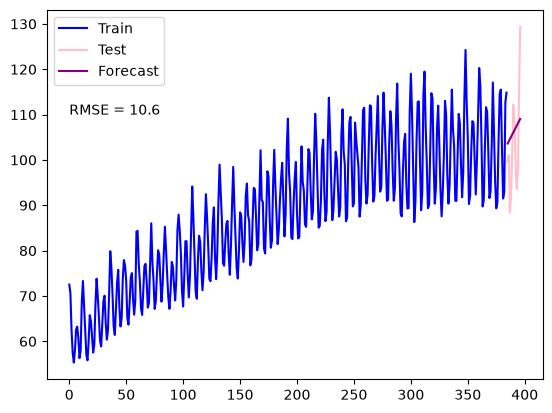

In [21]:

holt  = Holt(y_train, initialization_method='estimated',exponential=False) 
fit1 = holt.fit(smoothing_level=0.118889,smoothing_trend=0.227778)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,110, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()
